[1] CSV scenario32\scenario32_dev.csv: 3235 rows
    columns: ['index', 'unit1_rgb', 'unit1_pwr_60ghz', 'unit1_lidar', 'unit1_radar', 'unit1_loc', 'unit2_loc', 'unit1_beam', 'unit1_max_pwr', 'time_stamp', 'seq_index', 'unit2_spd_over_grnd_kmph', 'unit2_num_sats', 'unit2_altitude', 'unit2_geo_sep', 'unit2_mode_fix_type', 'unit2_pdop', 'unit2_hdop', 'unit2_vdop', 'unit2_interpolated_position']
    mapped: {'idx': 'index', 'seq': 'seq_index', 'rgb': 'unit1_rgb', 'pwr': 'unit1_pwr_60ghz', 'lidar': 'unit1_lidar', 'radar': 'unit1_radar', 'bs': 'unit1_loc', 'ue': 'unit2_loc', 'beam': 'unit1_beam', 'time': 'time_stamp', 'spd': 'unit2_spd_over_grnd_kmph', 'interp': 'unit2_interpolated_position'}

[2] LABELS  bad/missing power vectors: 21
    CSV beam == argmax + 1: 100.00 % of 3214 frames
    best vs second-best beam: median 0.07 dB | within 1 dB 100.0 % | within 0.1 dB 64.3 %  (near ties: top-1 cannot be much higher than this allows)
    peak over median beam: median 2.0 dB | under 3 dB 69.9 %

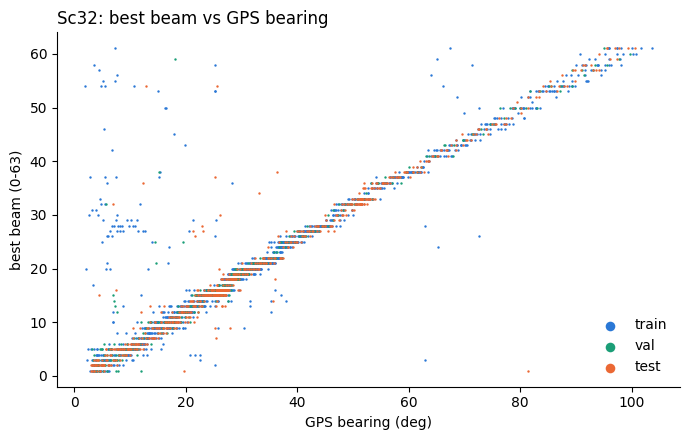

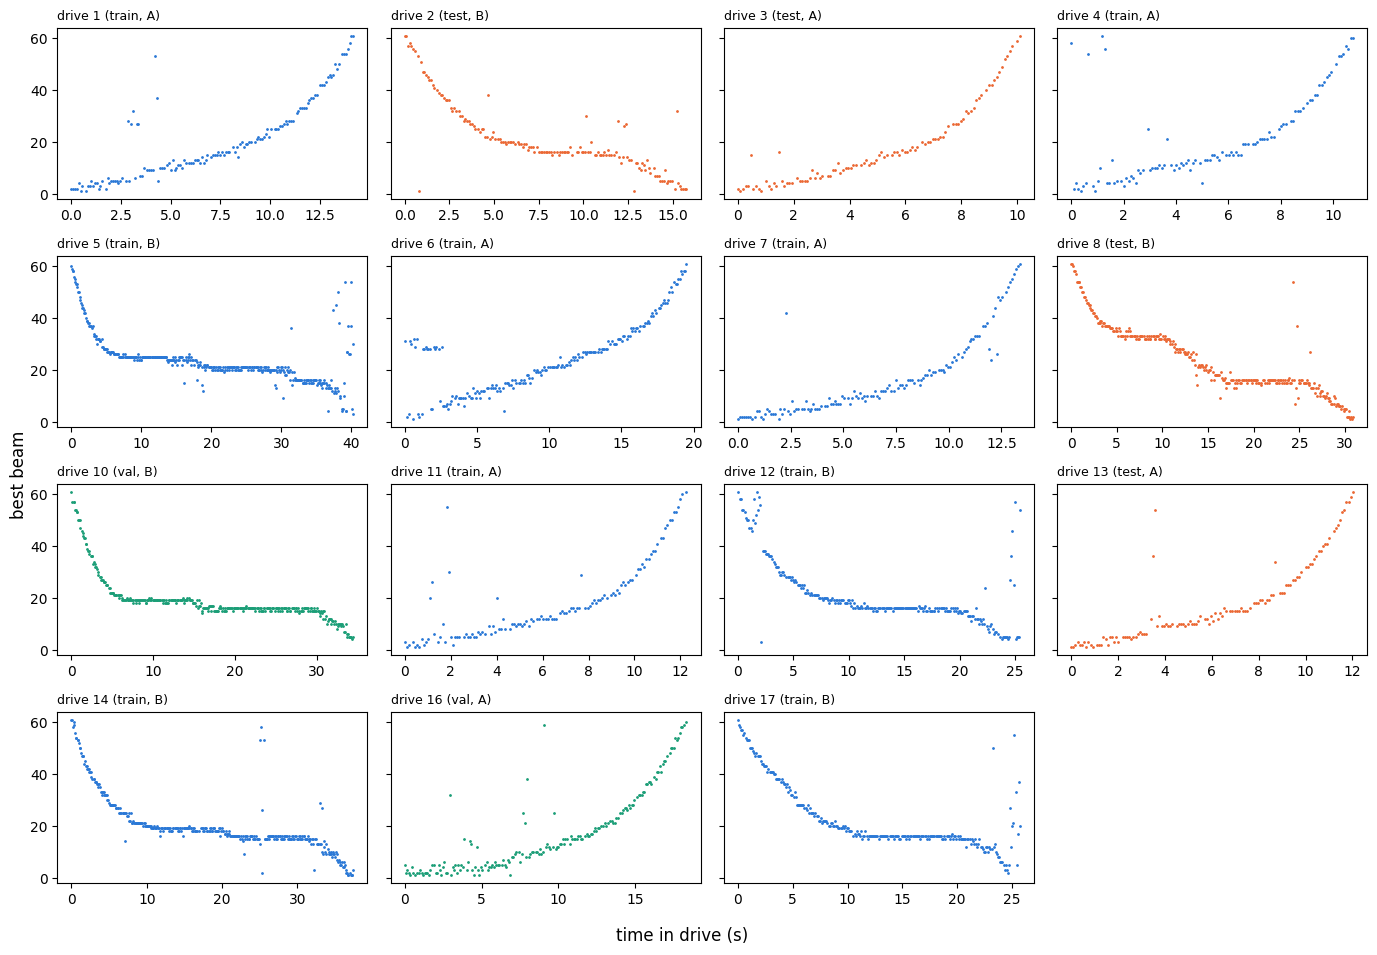


saved in S32/: S32_frames.csv, S32_power.npy, S32_split.json, S1_report.txt, S1_beam_vs_bearing.png, S1_drives.png


In [2]:
# ==== S1: AUDIT + CLEAN ONE DEEPSENSE SCENARIO FROM THE RAW FILES, AND FIX THE SPLIT (new pipeline, stage 1)
# run in the ODT folder (next to the scenario32 folder). needs: numpy, pandas, matplotlib
import os, re, sys, json, glob, argparse
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ap = argparse.ArgumentParser()
ap.add_argument("--scen", default="32")
ap.add_argument("--scen_dir", default=None, help="default: scenario<scen> next to this notebook")
ap.add_argument("--test_share", type=float, default=0.2, help="share of frames held out for testing (whole drives)")
ap.add_argument("--val_share", type=float, default=0.15, help="share of frames for validation (whole drives)")
ap.add_argument("--seed", type=int, default=0)
A = ap.parse_args([])   # notebook: settings are the defaults above
SD = A.scen_dir or f"scenario{A.scen}"
OUT = f"S{A.scen}"; os.makedirs(OUT, exist_ok=True)


class Tee:
    def __init__(self, path):
        self.f, self.o = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.o.write(s); self.f.write(s); self.f.flush()

    def flush(self):
        self.o.flush(); self.f.flush()


while hasattr(sys.stdout, "o"):
    sys.stdout = sys.stdout.o
sys.stdout = Tee(os.path.join(OUT, "S1_report.txt"))

# ------------------------------------------------------------------ 1. CSV
csvs = sorted(glob.glob(os.path.join(SD, "*.csv")))
assert csvs, f"no CSV in {SD}"
csv = next((c for c in csvs if "dev" in c.lower()), csvs[0])
raw = pd.read_csv(csv)
print(f"[1] CSV {csv}: {len(raw)} rows\n    columns: {list(raw.columns)}")


def find(*names):
    low = {c.lower(): c for c in raw.columns}
    for n in names:
        if n in low:
            return low[n]
    return None


C = dict(idx=find("index"), seq=find("seq_index"), rgb=find("unit1_rgb"), pwr=find("unit1_pwr_60ghz"),
         lidar=find("unit1_lidar"), radar=find("unit1_radar"), bs=find("unit1_loc"), ue=find("unit2_loc", "unit2_loc_1"),
         beam=find("unit1_beam"), time=find("time_stamp", "time_stamp[utc]"), spd=find("unit2_spd_over_grnd_kmph"),
         interp=find("unit2_interpolated_position"))
print(f"    mapped: {C}")
for k in ("idx", "seq", "pwr"):
    assert C[k], f"required column for '{k}' not found"


def fpath(p):
    p = str(p).strip()
    return os.path.join(SD, p[2:] if p.startswith("./") else p)


def nums(p):
    with open(fpath(p)) as f:
        return np.array([float(x) for x in re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", f.read())])


N = len(raw)
df = pd.DataFrame({"index": raw[C["idx"]].astype(int), "seq": raw[C["seq"]].astype(int)})

# ------------------------------------------------------------------ 2. labels from the 64 powers
P = np.full((N, 64), np.nan)
for i, p in enumerate(raw[C["pwr"]]):
    try:
        v = nums(p)
        if len(v) == 64 and np.all(np.isfinite(v)):
            P[i] = v
    except OSError:
        pass
bad = np.isnan(P).any(1)
Ps = np.sort(np.where(bad[:, None], 1.0, P), 1)
df["bad_power"] = bad
df["beam"] = np.where(bad, -1, np.nanargmax(np.where(bad[:, None], 0, P), 1))
df["pmax"] = np.where(bad, np.nan, Ps[:, -1])
df["snr_db"] = np.where(bad, np.nan, 10 * np.log10(Ps[:, -1] / np.maximum(np.median(Ps, 1), 1e-12)))
df["gap12_db"] = np.where(bad, np.nan, 10 * np.log10(Ps[:, -1] / np.maximum(Ps[:, -2], 1e-12)))
print(f"\n[2] LABELS  bad/missing power vectors: {bad.sum()}")
if C["beam"]:
    b = pd.to_numeric(raw[C["beam"]], errors="coerce").to_numpy(); ok = ~bad & np.isfinite(b)
    print(f"    CSV beam == argmax + 1: {100 * np.mean(b[ok] == df['beam'].to_numpy()[ok] + 1):.2f} % of {ok.sum()} frames")
g = df.loc[~bad, "gap12_db"]
print(f"    best vs second-best beam: median {g.median():.2f} dB | within 1 dB {100 * np.mean(g < 1):.1f} % | "
      f"within 0.1 dB {100 * np.mean(g < 0.1):.1f} %  (near ties: top-1 cannot be much higher than this allows)")
print(f"    peak over median beam: median {df['snr_db'].median():.1f} dB | under 3 dB {100 * np.mean(df.loc[~bad, 'snr_db'] < 3):.1f} %")

# ------------------------------------------------------------------ 3. time
def secs(v):
    """time stamp -> seconds of the day. Handles '11-46-30.874', '11-46-30-874356', '2022-06-08 11:46:30.874'"""
    n = re.findall(r"\d+", str(v))
    if len(n) >= 4 and len(n[-1]) >= 3:                    # last group is the fraction of a second
        h, m, s, f = n[-4:]
        return 3600 * int(h) + 60 * int(m) + int(s) + int(f) / 10 ** len(f)
    if len(n) >= 3:
        return 3600 * int(n[-3]) + 60 * int(n[-2]) + int(n[-1])
    return np.nan


ts = np.array([secs(v) for v in raw[C["time"]]]) if C["time"] else np.arange(N) * 0.1
same = np.r_[False, df["seq"].to_numpy()[1:] == df["seq"].to_numpy()[:-1]]
dt = np.r_[np.nan, np.diff(ts)]; dt[~same] = np.nan
df["dt"] = dt
df["repeat"] = same & (dt == 0)
df["gap"] = same & (dt > 0.3)
df["t"] = ts - df.groupby("seq")["seq"].transform(lambda s: ts[s.index[0]]).to_numpy()
back = int(np.sum(same & (dt < 0)))
drv = df.groupby("seq").size()
print(f"\n[3] TIME  first stamps: {raw[C['time']].head(3).tolist() if C['time'] else 'none'} -> seconds {np.round(ts[:3], 3).tolist()}")
dur = df.assign(ts=ts).groupby("seq")["ts"].agg(lambda x: x.max() - x.min())
print(f"    drive duration min/median/max {dur.min():.1f}/{dur.median():.1f}/{dur.max():.1f} s  (one pass should take about 10-40 s)")
print(f"    drives {len(drv)}: {drv.index.tolist()}")
print(f"    frames per drive min/median/max {drv.min()}/{int(drv.median())}/{drv.max()} | median dt {np.nanmedian(dt) * 1000:.0f} ms")
print(f"    repeated stamps {df['repeat'].sum()} | gaps > 0.3 s {df['gap'].sum()} | time going backwards {back}")
print(f"    drive appears again later (not contiguous): {int(sum(np.sum(np.diff(np.flatnonzero(df['seq'] == s)) > 1) > 0 for s in drv.index))}")

# ------------------------------------------------------------------ 4. GPS (reference only)
dist = np.full(N, np.nan); brg = np.full(N, np.nan)
if C["bs"] and C["ue"]:
    for i in range(N):
        try:
            bs, ue = nums(raw[C["bs"]].iloc[i])[:2], nums(raw[C["ue"]].iloc[i])[:2]
        except OSError:
            continue
        if len(bs) == 2 and len(ue) == 2:
            dx = np.radians(ue[1] - bs[1]) * np.cos(np.radians(bs[0])) * 6371000
            dy = np.radians(ue[0] - bs[0]) * 6371000
            dist[i], brg[i] = np.hypot(dx, dy), np.degrees(np.arctan2(dx, dy))
df["dist_m"], df["bearing_deg"] = dist, brg
df["speed_kmph"] = pd.to_numeric(raw[C["spd"]], errors="coerce") if C["spd"] else np.nan
df["gps_interp"] = raw[C["interp"]].astype(str).str.lower().isin(["1", "true", "yes", "1.0"]) if C["interp"] else False
gok = np.isfinite(dist)
print(f"\n[4] GPS (never a model input)  valid {100 * gok.mean():.1f} % | interpolated {100 * df['gps_interp'].mean():.1f} %")
print(f"    distance min/median/max {np.nanmin(dist):.1f}/{np.nanmedian(dist):.1f}/{np.nanmax(dist):.1f} m | "
      f"speed median {np.nanmedian(df['speed_kmph']):.1f} km/h")
m = gok & ~bad & ~df["gps_interp"].to_numpy()
if m.sum() > 10:
    k, c0 = np.polyfit(brg[m], df["beam"][m], 1)
    print(f"    corr(bearing, beam) {np.corrcoef(brg[m], df['beam'][m])[0, 1]:.3f} | beam = {c0:.1f} + {k:.3f} * bearing  (non-interpolated frames)")

# ------------------------------------------------------------------ 5. sensor files present
for key, colname in (("img", "rgb"), ("lidar", "lidar"), ("radar", "radar")):
    df[f"has_{key}"] = [os.path.exists(fpath(p)) for p in raw[C[colname]]] if C[colname] else False
print(f"\n[5] FILES  image {100 * df['has_img'].mean():.1f} % | lidar {100 * df['has_lidar'].mean():.1f} % | radar {100 * df['has_radar'].mean():.1f} %")
df["img_path"] = raw[C["rgb"]] if C["rgb"] else ""
df["lidar_path"] = raw[C["lidar"]] if C["lidar"] else ""
df["radar_path"] = raw[C["radar"]] if C["radar"] else ""

# ------------------------------------------------------------------ 6. usable frames + split by whole drives, per direction
df["usable"] = ~df["bad_power"] & ~df["repeat"]
u = df["usable"]
size = df[u].groupby("seq").size()
# direction of each drive: does the beam rise (A) or fall (B) over the drive?
dirn = {}
for d in size.index:
    mm = u & (df["seq"] == d)
    dirn[int(d)] = "A (beam rises)" if np.corrcoef(df.loc[mm, "t"], df.loc[mm, "beam"])[0, 1] > 0 else "B (beam falls)"
df["direction"] = df["seq"].map(dirn)
rng = np.random.default_rng(A.seed)
TE, VA = [], []
for grp in sorted(set(dirn.values())):                    # same shares inside each direction
    ds_g = [d for d in size.index if dirn[int(d)] == grp]; tot = size[ds_g].sum()
    best = None
    for _ in range(3000):
        order = rng.permutation(ds_g); te, va, acc, acc2 = [], [], 0, 0
        for d in order:
            if acc < A.test_share * tot:
                te.append(int(d)); acc += size[d]
        for d in order[len(te):]:
            if acc2 < A.val_share * tot:
                va.append(int(d)); acc2 += size[d]
        err = abs(acc / tot - A.test_share) + abs(acc2 / tot - A.val_share)
        if best is None or err < best[0]:
            best = (err, te, va)
    TE += best[1]; VA += best[2]
TE, VA = sorted(TE), sorted(VA)
TR = sorted(int(d) for d in size.index if d not in TE + VA)
df["split"] = np.where(df["seq"].isin(TE), "test", np.where(df["seq"].isin(VA), "val", "train"))
json.dump(dict(scenario=A.scen, seed=A.seed, train=TR, val=VA, test=TE, direction=dirn),
          open(os.path.join(OUT, f"S{A.scen}_split.json"), "w"), indent=1)
print(f"\n[6] SPLIT (whole drives, stratified by direction, seed {A.seed}, fixed from now on)")
for grp in sorted(set(dirn.values())):
    print(f"    {grp}: drives {[d for d in dirn if dirn[d] == grp]}")
for nm, ds in (("train", TR), ("val", VA), ("test", TE)):
    mm = u & df["seq"].isin(ds)
    nA = sum(dirn[d].startswith("A") for d in ds)
    print(f"    {nm:5s} drives {ds} ({nA} A, {len(ds) - nA} B) | {mm.sum()} frames ({100 * mm.sum() / u.sum():.1f} %) | "
          f"beams {df.loc[mm, 'beam'].min()}-{df.loc[mm, 'beam'].max()}")
unseen = set(df.loc[u & (df["split"] == "test"), "beam"]) - set(df.loc[u & (df["split"] == "train"), "beam"])
print(f"    test beams never seen in training: {sorted(int(b) for b in unseen) or 'none'}")
print(f"\n    usable frames {u.sum()} of {N} (dropped: bad power {df['bad_power'].sum()}, repeated stamp {(df['repeat'] & ~df['bad_power']).sum()})")

df.to_csv(os.path.join(OUT, f"S{A.scen}_frames.csv"), index=False)
np.save(os.path.join(OUT, f"S{A.scen}_power.npy"), P.astype(np.float32))

# ------------------------------------------------------------------ 7. figures
col = {"train": "#2a78d6", "val": "#1b9e77", "test": "#eb6834"}
fig, ax = plt.subplots(figsize=(7, 4.5))
for nm in col:
    mm = u & (df["split"] == nm) & np.isfinite(df["bearing_deg"])
    ax.scatter(df.loc[mm, "bearing_deg"], df.loc[mm, "beam"], s=3, color=col[nm], label=nm, lw=0)
ax.set_xlabel("GPS bearing (deg)"); ax.set_ylabel("best beam (0-63)"); ax.legend(frameon=False, markerscale=4)
ax.set_title(f"Sc{A.scen}: best beam vs GPS bearing", loc="left"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "S1_beam_vs_bearing.png"), dpi=150); plt.show()
ds = list(drv.index); nc = 4; nr = int(np.ceil(len(ds) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(14, 2.4 * nr), sharey=True, squeeze=False)
for a_, d in zip(axs.flat, ds):
    mm = u & (df["seq"] == d)
    a_.plot(df.loc[mm, "t"], df.loc[mm, "beam"], ".", ms=2, color=col[df.loc[mm, "split"].iloc[0]])
    a_.set_title(f"drive {d} ({df.loc[mm, 'split'].iloc[0]}, {dirn[int(d)][0]})", fontsize=9, loc="left")
for a_ in axs.flat[len(ds):]:
    a_.axis("off")
fig.supxlabel("time in drive (s)"); fig.supylabel("best beam")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "S1_drives.png"), dpi=130); plt.show()
print(f"\nsaved in {OUT}/: S{A.scen}_frames.csv, S{A.scen}_power.npy, S{A.scen}_split.json, S1_report.txt, S1_beam_vs_bearing.png, S1_drives.png")

while hasattr(sys.stdout, "o"):        # back to normal printing
    sys.stdout = sys.stdout.o